No comments found. Using sample comments for demonstration.

--- Sentiment Analysis Results ---
                                       Comment Sentiment
           I love this post! Very informative.  Positive
This article is terrible and full of mistakes.  Negative
      Pretty good, but it needs more examples.  Positive
        I completely disagree with the author.  Positive
    Excellent explanation, thanks for sharing!  Positive

--- Sentiment Counts ---
Sentiment
Positive    4
Negative    1
Neutral     0
Name: count, dtype: int64


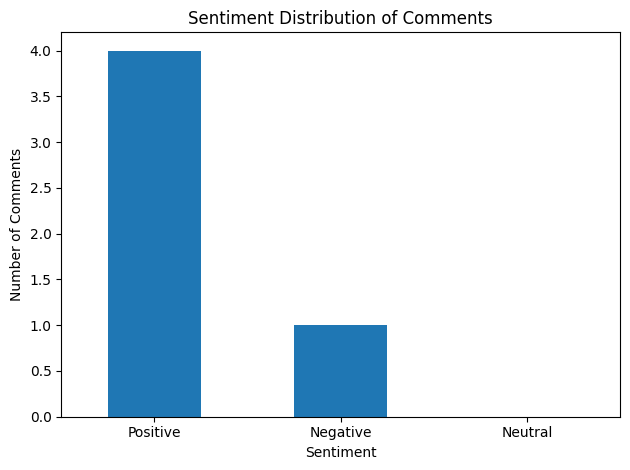

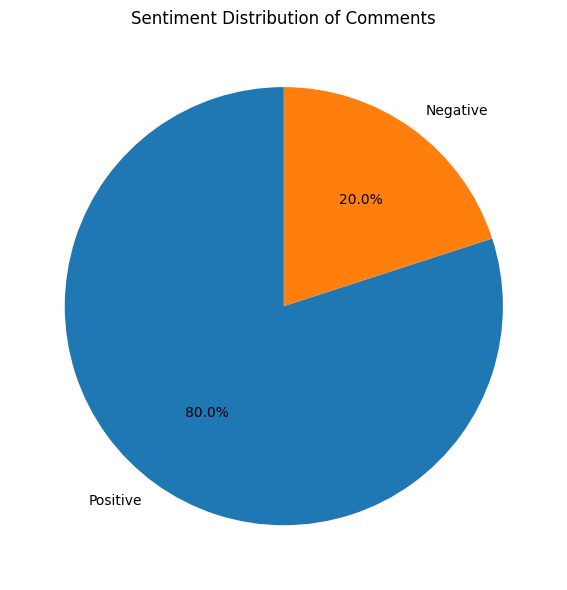

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from textblob import TextBlob

# 1. Get comments from website
url = "https://www.sahyadri.edu.in/"

try:
    soup = BeautifulSoup(requests.get(url,headers={"User-Agent": "Mozilla/5.0"}, 
                                      timeout=15).text, "html.parser")
    comments = [c.get_text(" ", strip=True)
                for c in soup.select("p.comment-text") if c.get_text(strip=True)]
except requests.RequestException:
    comments = []

# 2. Sample comments if not found
if not comments:
    print("No comments found. Using sample comments for demonstration.")
    comments = [
        "I love this post! Very informative.",
        "This article is terrible and full of mistakes.",
        "Pretty good, but it needs more examples.",
        "I completely disagree with the author.",
        "Excellent explanation, thanks for sharing!"
    ]

# 3. Analyze sentiment
def analyze(c):
    p = TextBlob(c).sentiment.polarity
    return "Positive" if p > 0 else "Negative" if p < 0 else "Neutral"

# 4. Create DataFrame
df = pd.DataFrame({
    "Comment": comments,
    "Sentiment": [analyze(c) for c in comments]
})

print("\n--- Sentiment Analysis Results ---")
print(df.to_string(index=False))

# 5. Count sentiments
counts = df["Sentiment"].value_counts().reindex(
    ["Positive", "Negative", "Neutral"], fill_value=0)

print("\n--- Sentiment Counts ---")
print(counts)

# 6. Bar chart
counts.plot(kind="bar", rot=0)
plt.title("Sentiment Distribution of Comments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

# 7. Pie chart
counts[counts > 0].plot(kind="pie", autopct="%1.1f%%",
                         startangle=90, figsize=(6, 6))
plt.title("Sentiment Distribution of Comments")
plt.ylabel("")
plt.tight_layout()
plt.show()